# How to learn from this notebook

**Audience:** familiar with ML theory, new to the Python/PyTorch tools. Read [Start here](learning/START_HERE.md) once. The format is **learn the API → inspect a small worked example → implement your task → explain the result**. You are not expected to guess unfamiliar package methods. Your existing answers are preserved.

**This is the practical foundation.** New Learn first blocks appear before plotting, classes/Module, inference, loss/optimizers, one update, the loop, and checkpoint loading. Use the class outline in Task 7 as a scaffold; the one-parameter worked example teaches object mechanics without completing your two-parameter regression task. After this lesson and Chapter 02, you can begin a small CS189/AI-project application.

# Practice outline: pytorch workflow

This lesson is a sequence of small implementations. Keep the explanatory text as reference, then follow **Your task** immediately above each code cell. You write the implementation; the task names the inputs, APIs, and result to inspect.

| Tasks | What you will build |
| --- | --- |
| [Tasks 1–6](#practice-task-1) | Prepare and visualize labelled data |
| [Tasks 7–13](#practice-task-7) | Build and inspect an untrained model |
| [Tasks 14–19](#practice-task-14) | Train and evaluate the first model |
| [Tasks 20–24](#practice-task-20) | Save, reload, and compare predictions |
| [Tasks 25–40](#practice-task-25) | Repeat using nn.Linear and your chosen device |

**How to work:** run cells from top to bottom, keep the specified names so later cells can reuse them, and inspect each checkpoint before continuing. Existing code and outputs are preserved. A checkpoint is a result to examine, not a separate test suite. For longer training tasks, write the loop step by step in the same cell.

**On your Mac:** choose CUDA if available, otherwise MPS if available, otherwise CPU. Keep model/input/target devices aligned; use CPU copies when plotting or converting to NumPy. Use `num_workers=0` for notebook DataLoaders. Run lessons with this repository as the working directory. Shared course helpers are supplied in `helper_functions.py` and `going_modular/`; they are support code, not cells you need to fill in.

**Notation:** $N$ is batch/sample count; $C$ is channel/class count as stated locally; image tensors use batch, channels, height, width order. Class-index targets use `torch.int64`; regression and binary-loss targets use `torch.float32`. Accuracy units are stated in each task—do not mix fractions with percentages.

See [LEARNING_GUIDE.md](LEARNING_GUIDE.md) for saving and resuming locally.



<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/01_pytorch_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[View Source Code](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/01_pytorch_workflow.ipynb) | [View Slides](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/slides/01_pytorch_workflow.pdf) | [Watch Video Walkthrough](https://youtu.be/Z_ikDlimN6A?t=15419) 

# 01. PyTorch Workflow Fundamentals

The essence of machine learning and deep learning is to take some data from the past, build an algorithm (like a neural network) to discover patterns in it and use the discovered patterns to predict the future.

There are many ways to do this and many new ways are being discovered all the time.

But let's start small.

How about we start with a straight line?

And we see if we can build a PyTorch model that learns the pattern of the straight line and matches it.

## What we're going to cover

In this module we're going to cover a standard PyTorch workflow (it can be chopped and changed as necessary but it covers the main outline of steps).

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01_a_pytorch_workflow.png" width=900 alt="a pytorch workflow flowchat"/>

For now, we'll use this workflow to predict a simple straight line but the workflow steps can be repeated and changed depending on the problem you're working on.

Specifically, we're going to cover:

| **Topic** | **Contents** |
| ----- | ----- |
| **1. Getting data ready** | Data can be almost anything but to get started we're going to create a simple straight line |
| **2. Building a model** | Here we'll create a model to learn patterns in the data, we'll also choose a **loss function**, **optimizer** and build a **training loop**. | 
| **3. Fitting the model to data (training)** | We've got data and a model, now let's let the model (try to) find patterns in the (**training**) data. |
| **4. Making predictions and evaluating a model (inference)** | Our model's found patterns in the data, let's compare its findings to the actual (**testing**) data. |
| **5. Saving and loading a model** | You may want to use your model elsewhere, or come back to it later, here we'll cover that. |
| **6. Putting it all together** | Let's take all of the above and combine it. |


## Where can you get help?

All of the materials for this course are [available on GitHub](https://github.com/mrdbourke/pytorch-deep-learning).

And if you run into trouble, you can ask a question on the [Discussions page](https://github.com/mrdbourke/pytorch-deep-learning/discussions) there too.

There's also the [PyTorch developer forums](https://discuss.pytorch.org/), a very helpful place for all things PyTorch. 

Let's start by putting what we're covering into a dictionary to reference later.


<a id="practice-task-1"></a>

**Your task 1 — write in the next code cell**

Write a short ordered list of the workflow you will implement: prepare data, split it, build a model, train, evaluate, and save/reload.

**Inspect when finished:** You can describe what goes into and comes out of each stage.


And now let's import what we'll need for this module.

We're going to get `torch`, `torch.nn` (`nn` stands for neural network and this package contains the building blocks for creating neural networks in PyTorch) and `matplotlib`.

### Learn first: imports, functions, and help
A package is a collection of Python code. `import torch` makes its name available **in this kernel**; it does not install it. `from torch import nn` gives you the neural-network namespace, so `nn.Linear` is the same class as `torch.nn.Linear`. `import matplotlib.pyplot as plt` gives the plotting interface the shorter name `plt`.

In `torch.arange(start=0, end=1, step=0.02)`, the names before `=` are **keyword argument names** defined by that function. They are not new variables in your notebook. Compare `torch.arange(0, 1, 0.02)`, which supplies the same arguments by position.

To discover a signature, place the cursor inside its parentheses and press **Shift+Tab**. If that does not show useful information, run `help(torch.arange)` in a separate cell. For an object you already created, `type(obj)`, `obj.shape`, and `obj.dtype` help explain what it is. Some PyTorch functions are implemented in compiled code, so their displayed signature may be less helpful than their documentation.

**Try first:** import the three names and evaluate `torch.__version__`. Then continue to the task below.

<a id="practice-task-2"></a>

**Your task 2 — write in the next code cell**

Import torch, nn from torch, and matplotlib.pyplot as plt. Display the PyTorch version.

**Inspect when finished:** The next cells can use torch, nn, and plt.


In [25]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__

Matplotlib is building the font cache; this may take a moment.


'2.15.0'

## 1. Data (preparing and loading)

I want to stress that "data" in machine learning can be almost anything you can imagine. A table of numbers (like a big Excel spreadsheet), images of any kind, videos (YouTube has lots of data!), audio files like songs or podcasts, protein structures, text and more.

![machine learning is a game of two parts: 1. turn your data into a representative set of numbers and 2. build or pick a model to learn the representation as best as possible](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-machine-learning-a-game-of-two-parts.png)

Machine learning is a game of two parts: 
1. Turn your data, whatever it is, into numbers (a representation).
2. Pick or build a model to learn the representation as best as possible.

Sometimes one and two can be done at the same time.

But what if you don't have data?

Well, that's where we're at now.

No data.

But we can create some.

Let's create our data as a straight line.

We'll use [linear regression](https://en.wikipedia.org/wiki/Linear_regression) to create the data with known **parameters** (things that can be learned by a model) and then we'll use PyTorch to see if we can build model to estimate these parameters using [**gradient descent**](https://en.wikipedia.org/wiki/Gradient_descent).

Don't worry if the terms above don't mean much now, we'll see them in action and I'll put extra resources below where you can learn more.



### Learn first: turn your mathematical dataset into tensors
Here a row is one sample, and a column is one input feature. We need float32 `X` of shape $(50,1)$ and matching float32 `y` of shape $(50,1)$. The first axis is sample count; the second is feature/output count.

| API | Arguments you supply | What comes back |
| --- | --- | --- |
| `torch.arange(start, end, step, dtype=...)` | Start, excluded end, increment, optional dtype | A one-dimensional tensor of regularly spaced numbers |
| `tensor.unsqueeze(dim)` | Position of the new size-one axis | A tensor with one additional dimension |
| `tensor.reshape(...)` | Desired dimension sizes, preserving element count | A reshaped tensor |

A miniature example, **not the dataset for your task**:

```python
sample_inputs = torch.arange(0, 3, dtype=torch.float32)
print(sample_inputs.shape)              # (3,)
sample_inputs = sample_inputs.unsqueeze(1)
print(sample_inputs.shape)              # (3, 1)
sample_targets = 2 * sample_inputs + 1
```

Your task uses different values: start zero, excluded end one, step 0.02, slope 0.7, intercept 0.3. You may use your existing reshape implementation; you do not need to rewrite working code to match the example's style.

<a id="practice-task-3"></a>

**Your task 3 — write in the next code cell**

Set weight to 0.7 and bias to 0.3. Create float32 X from 0 up to but excluding 1 in steps of 0.02, then add a final dimension. Calculate y using $y=0.7X+0.3$. Display the first ten pairs.

**Inspect when finished:** X and y both have shape $(50,1)$; the first target is 0.3.


In [12]:
X = torch.arange(start=0,end=1,step=0.02, dtype=torch.float32).reshape((50,1))

y = 0.7 * X + 0.3
for i in range(0,10):
    print(f"value of y[{i}]: {y[i]}")

value of y[0]: tensor([0.3000])
value of y[1]: tensor([0.3140])
value of y[2]: tensor([0.3280])
value of y[3]: tensor([0.3420])
value of y[4]: tensor([0.3560])
value of y[5]: tensor([0.3700])
value of y[6]: tensor([0.3840])
value of y[7]: tensor([0.3980])
value of y[8]: tensor([0.4120])
value of y[9]: tensor([0.4260])


Beautiful! Now we're going to move towards building a model that can learn the relationship between `X` (**features**) and `y` (**labels**). 

### Split data into training and test sets 

We've got some data.

But before we build a model we need to split it up.

One of most important steps in a machine learning project is creating a training and test set (and when required, a validation set).

Each split of the dataset serves a specific purpose:

| Split | Purpose | Amount of total data | How often is it used? |
| ----- | ----- | ----- | ----- |
| **Training set** | The model learns from this data (like the course materials you study during the semester). | ~60-80% | Always |
| **Validation set** | The model gets tuned on this data (like the practice exam you take before the final exam). | ~10-20% | Often but not always |
| **Testing set** | The model gets evaluated on this data to test what it has learned (like the final exam you take at the end of the semester). | ~10-20% | Always |

For now, we'll just use a training and test set, this means we'll have a dataset for our model to learn on as well as be evaluated on.

We can create them by splitting our `X` and `y` tensors.

> **Note:** When dealing with real-world data, this step is typically done right at the start of a project (the test set should always be kept separate from all other data). We want our model to learn from training data and then evaluate it on test data to get an indication of how well it **generalizes** to unseen examples.


### Learn first: slicing a dataset without changing its feature dimension
For `X` of shape $(50,1)$, `X[:k]` means the first `k` **rows** and every remaining column. It is shorthand for `X[:k, :]`; no flattening is necessary. `X[k:]` selects the rest of the rows.

Calculate `k` using `int(0.8 * len(X))`. Multiplication by 0.8 produces a float, but Python slice boundaries need integers. Use that same boundary for `X` and `y` to preserve sample/target pairing. Basic slices share storage; `.clone()` makes independent storage if you want it, but training normally modifies model parameters rather than dataset values.

**Before continuing:** inspect all four shapes and confirm the feature dimension remains one.

<a id="practice-task-4"></a>

**Your task 4 — write in the next code cell**

Use the first 80% of X and y for X_train and y_train; use the rest for X_test and y_test. Create train_split and print all four lengths.

**Inspect when finished:** There are 40 training pairs and 10 test pairs; features and labels stay aligned.


In [16]:
train_split = int(0.8 * len(X))

X_train = X[:train_split].clone()
X_test = X[train_split:].clone()

y_train = y[:train_split].clone()
y_test = y[train_split:].clone()


Wonderful, we've got 40 samples for training (`X_train` & `y_train`) and 10 samples for testing (`X_test` & `y_test`).

The model we create is going to try and learn the relationship between `X_train` & `y_train` and then we will evaluate what it learns on `X_test` and `y_test`.

But right now our data is just numbers on a page.

Let's create a function to visualize it.

### Learn first: draw a plot, then wrap it in a function
You do not need prior matplotlib experience. A **figure** is a plotting canvas. A **scatter plot** draws one dot for each paired horizontal/vertical value.

Run this small worked example in a temporary cell if plotting is new:

```python
plt.figure(figsize=(6, 4))
plt.scatter([0, 1, 2], [1, 3, 5], color="purple", label="Example points")
plt.xlabel("input")
plt.ylabel("target")
plt.legend()
plt.show()
```

| Call | How to use it |
| --- | --- |
| `plt.figure(figsize=(width, height))` | Create a fresh canvas; dimensions are in inches |
| `plt.scatter(x, y, color=..., label=...)` | Equal-length horizontal/vertical positions; one series of points |
| `plt.xlabel(text)` / `plt.ylabel(text)` | Axis labels as strings |
| `plt.legend()` | Display the series labels supplied earlier |
| `plt.show()` | Display the completed figure |

Now make that plotting sequence reusable. A Python function's parameters are local names for values supplied by the caller:

```python
def show_points(inputs, targets):
    plt.figure()
    plt.scatter(inputs, targets)
    plt.show()

# Calling show_points(X_train, y_train) makes inputs refer to X_train
# and targets refer to y_train inside the function.
```

For **your** `plot_predictions`, implement in three increments:

1. Draw the training pairs in blue. Call the function and inspect the plot.
2. Add the test pairs in green, then axis labels and a legend.
3. Add `predictions=None` as an optional argument. Inside `if predictions is not None:`, draw red dots with **test inputs as horizontal positions** and predictions as vertical positions. Put `plt.show()` last.

Choose either of these interfaces and keep later calls consistent:

- Explicit arguments: `plot_predictions(X_train, y_train, X_test, y_test)`.
- Default dataset arguments: define defaults such as `train_data=X_train`, allowing `plot_predictions()`.

Parameter names can differ from mine—your `training_data` is fine. Python keyword calls must use **your function's exact parameter names**. Optional type hints are not needed; if you use one for a tensor, the type is `torch.Tensor`, while `torch.tensor` is a function.

<a id="practice-task-5"></a>

**Your task 5 — write in the next code cell**

Define plot_predictions(train_data, train_labels, test_data, test_labels, predictions=None), using either explicit dataset arguments or defaults, as explained above. Plot training points in blue, test points in green, and optional predictions in red. Add a legend.

**Inspect when finished:** The function accepts CPU tensors; predictions are plotted against test_data, not training inputs.


In [30]:
def plot_predictions(training_data: torch.tensor, training_labels: torch.tensor, test_data: torch.tensor, test_labels: torch.tensor, predictions=None):
    plt.figure(figsize=(10,7))
    plt.scatter(training_data, training_labels, color="blue", label="Training data")
    plt.scatter(test_data, test_labels, color="green", label="Test data")

    plt.xlabel("X")
    plt.ylabel("y")
    plt.legend()
    plt.show()

### Apply: call the function you actually defined
Defining a function stores its instructions; it does not execute the plotting body. Call it now. If your definition has four required dataset arguments, pass all four. If you gave those arguments defaults, you can omit them. At this stage omit `predictions` because the model has not made any yet.

**Question:** which four variables does the function read through its arguments? Which variables are temporary names inside it?

<a id="practice-task-6"></a>

**Your task 6 — write in the next code cell**

Call plot_predictions with your four split tensors if required by your definition; leave the optional predictions argument unset.

**Inspect when finished:** The plot shows one straight line, with the final ten points marked as test data.


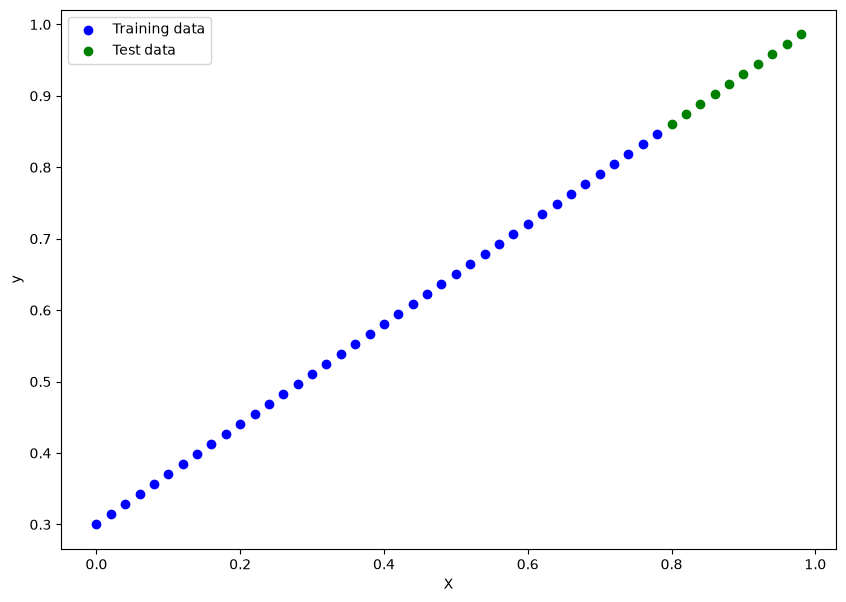

In [31]:
plot_predictions(X_train, y_train, X_test, y_test)

Epic!

Now instead of just being numbers on a page, our data is a straight line.

> **Note:** Now's a good time to introduce you to the data explorer's motto... "visualize, visualize, visualize!"
> 
> Think of this whenever you're working with data and turning it into numbers, if you can visualize something, it can do wonders for understanding.
>
> Machines love numbers and we humans like numbers too but we also like to look at things.

## 2. Build model

Now we've got some data, let's build a model to use the blue dots to predict the green dots.

We're going to jump right in.

We'll write the code first and then explain everything. 

Let's replicate a standard linear regression model using pure PyTorch.

### Learn first: a Python class, then a PyTorch model
You know the regression formula. The unfamiliar part is how Python stores its parameters and how PyTorch discovers them. Read these two examples before writing your model.

**A class describes an object.** `__init__` runs when a new object is created. `self` is the particular object whose method is executing. Attributes such as `self.amount` persist on that object and can be read by its other methods.

```python
class Counter:
    def __init__(self, initial):
        self.amount = initial

    def add(self, increment):
        return self.amount + increment

counter_a = Counter(10)       # Python runs __init__(counter_a, 10)
print(counter_a.add(3))       # Python supplies self=counter_a; you supply 3
print(counter_a.amount)      # 10: add returned a result without reassigning amount
```

`self.amount` is not a global variable and is not local to `__init__`; it is an attribute stored on `counter_a`. Another Counter instance can have its own amount.

**`nn.Module` is PyTorch's base class for models/layers.** Inheriting from it gives your object parameter discovery, device movement, train/eval modes, and checkpoint support. `super().__init__()` initializes that base-class machinery before you register your own components.

Here is a **complete one-parameter example** that learns only a scale, not the two-parameter regression in your task:

```python
class ScaleOnly(nn.Module):
    def __init__(self):
        super().__init__()
        self.scale = nn.Parameter(torch.randn(1))

    def forward(self, inputs):
        return self.scale * inputs

scale_demo = ScaleOnly()
print(scale_demo.scale)
print(scale_demo(torch.tensor([[2.0], [4.0]])))
```

| Piece | What it does |
| --- | --- |
| `torch.randn(1)` | Produces a float32 tensor of shape $(1,)$ from a standard normal distribution |
| `nn.Parameter(tensor)` | Marks a tensor as a learnable model parameter; gradients are enabled by default |
| `self.scale = ...` | Registers that parameter on this model instance |
| `forward(self, inputs)` | Describes how to calculate predictions using stored parameters |
| `scale_demo(inputs)` | Calls the model; PyTorch dispatches to its `forward` method |

Creating an instance initializes its parameters **once**. Calling it does not randomly reinitialize them. A regular tensor attribute would not automatically be registered as a learnable parameter.

**Now build your own regression model in the next cell:**

1. Define `LinearRegressionModel` as a subclass of `nn.Module`.
2. In `__init__`, call the base initializer, then create **two** one-element `nn.Parameter` attributes: `self.weights` and `self.bias`.
3. Define `forward(self, x)` at the **same indentation level as `__init__`**, not inside it.
4. Return the regression calculation using those stored attributes: $\hat y=\text{weights}\,x+\text{bias}$.

You can start with this outline; replace each `...` yourself:

```python
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = ...
        self.bias = ...

    def forward(self, x):
        ...
```

**Common mistakes to check:** use `torch.randn(1)` with parentheses; spell `weights` consistently; use the same class-name capitalization when instantiating it. `self.weight` and `self.weights` are different attribute names. A nested `def forward` inside `__init__` does not define the model's forward method.

**What this cell does not do yet:** no optimizer has run, so the random parameters have not learned the true slope/intercept.

<a id="practice-task-7"></a>

**Your task 7 — write in the next code cell**

Define LinearRegressionModel as an nn.Module. In __init__, register one random float32 weight and one random float32 bias as nn.Parameter attributes named weights and bias. Implement forward(self, x) using $\hat y=wx+b$.

**Inspect when finished:** Input shape $(N,1)$ produces output shape $(N,1)$; both parameters are trainable.


In [38]:
class LinearregressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float32))
        self.bias = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float32))

        def forward(self, x: torch.Tensor) -> torch.Tensor:
            return self.weight * x + self.bias
    

Alright there's a fair bit going on above but let's break it down bit by bit.

> **Resource:** We'll be using Python classes to create bits and pieces for building neural networks. If you're unfamiliar with Python class notation, I'd recommend reading [Real Python's Object Orientating programming in Python 3 guide](https://realpython.com/python3-object-oriented-programming/) a few times.



### PyTorch model building essentials

PyTorch has four (give or take) essential modules you can use to create almost any kind of neural network you can imagine.

They are [`torch.nn`](https://pytorch.org/docs/stable/nn.html), [`torch.optim`](https://pytorch.org/docs/stable/optim.html), [`torch.utils.data.Dataset`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) and [`torch.utils.data.DataLoader`](https://pytorch.org/docs/stable/data.html). For now, we'll focus on the first two and get to the other two later (though you may be able to guess what they do).

| PyTorch module | What does it do? |
| ----- | ----- |
| [`torch.nn`](https://pytorch.org/docs/stable/nn.html) | Contains all of the building blocks for computational graphs (essentially a series of computations executed in a particular way). |
| [`torch.nn.Parameter`](https://pytorch.org/docs/stable/generated/torch.nn.parameter.Parameter.html#parameter) | Stores tensors that can be used with `nn.Module`. If `requires_grad=True` gradients (used for updating model parameters via [**gradient descent**](https://ml-cheatsheet.readthedocs.io/en/latest/gradient_descent.html))  are calculated automatically, this is often referred to as "autograd".  | 
| [`torch.nn.Module`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module) | The base class for all neural network modules, all the building blocks for neural networks are subclasses. If you're building a neural network in PyTorch, your models should subclass `nn.Module`. Requires a `forward()` method be implemented. | 
| [`torch.optim`](https://pytorch.org/docs/stable/optim.html) | Contains various optimization algorithms (these tell the model parameters stored in `nn.Parameter` how to best change to improve gradient descent and in turn reduce the loss). | 
| `def forward()` | All `nn.Module` subclasses require a `forward()` method, this defines the computation that will take place on the data passed to the particular `nn.Module` (e.g. the linear regression formula above). |

If the above sounds complex, think of like this, almost everything in a PyTorch neural network comes from `torch.nn`,
* `nn.Module` contains the larger building blocks (layers)
* `nn.Parameter` contains the smaller parameters like weights and biases (put these together to make `nn.Module`(s))
* `forward()` tells the larger blocks how to make calculations on inputs (tensors full of data) within  `nn.Module`(s)
* `torch.optim` contains optimization methods on how to improve the parameters within `nn.Parameter` to better represent input data 

![a pytorch linear model with annotations](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-linear-model-annotated.png)
*Basic building blocks of creating a PyTorch model by subclassing `nn.Module`. For objects that subclass `nn.Module`, the `forward()` method must be defined.*

> **Resource:** See more of these essential modules and their use cases in the [PyTorch Cheat Sheet](https://pytorch.org/tutorials/beginner/ptcheat.html). 



### Checking the contents of a PyTorch model
Now we've got these out of the way, let's create a model instance with the class we've made and check its parameters using [`.parameters()`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.parameters). 

### Learn first: instantiate the model and inspect its parameters
The class is a reusable blueprint. `LinearRegressionModel()` creates one object; store it as `model_0`. If you used another class spelling, either rename the definition or use your spelling consistently.

`model_0.parameters()` returns an **iterator** over registered parameters. `list(...)` materializes it so you can inspect both tensors. Do not call `nn.Parameter` again here: the constructor already created the parameters.

Set `torch.manual_seed(42)` immediately before construction if you want the same initial state on repeated runs. The seed controls initialization, not whether training is enabled.

<a id="practice-task-8"></a>

**Your task 8 — write in the next code cell**

Set the seed to 42, instantiate model_0, and display its parameters.

**Inspect when finished:** There are two trainable one-element tensors. Recreating after resetting the seed reproduces them.


In [39]:
torch.manual_seed(42)
model_0 = LinearRegressionModel()

NameError: name 'LinearRegressionModel' is not defined

We can also get the state (what the model contains) of the model using [`.state_dict()`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.state_dict).

### Learn first: a model's state dictionary
`model_0.state_dict()` returns a dictionary mapping parameter/buffer names to tensors. In your model, look for `weights` and `bias`. It is a convenient view of the model's learned state, not another forward pass.

Compare `list(model_0.parameters())` with `model_0.state_dict()`: the former is useful for optimizers; the latter includes names and is used for saving/loading.

<a id="practice-task-9"></a>

**Your task 9 — write in the next code cell**

Inspect model_0.state_dict(). Identify which entry is the slope and which is the intercept.

**Inspect when finished:** The dictionary has weights and bias entries; these are not yet fitted to the data.


Notice how the values for `weights` and `bias` from `model_0.state_dict()` come out as random float tensors?

This is because we initialized them above using `torch.randn()`.

Essentially we want to start from random parameters and get the model to update them towards parameters that fit our data best (the hardcoded `weight` and `bias` values we set when creating our straight line data).

> **Exercise:** Try changing the `torch.manual_seed()` value two cells above, see what happens to the weights and bias values. 

Because our model starts with random values, right now it'll have poor predictive power.



### Making predictions using `torch.inference_mode()` 
To check this we can pass it the test data `X_test` to see how closely it predicts `y_test`.

When we pass data to our model, it'll go through the model's `forward()` method and produce a result using the computation we've defined. 

Let's make some predictions. 

### Learn first: inference is a model call without gradient recording
A forward call usually records operations needed to compute gradients of trainable parameters. For predictions you do not intend to backpropagate through, use this context-manager structure:

```python
with torch.inference_mode():
    demo_output = scale_demo(torch.tensor([[3.0]]))
```

`with` applies its context only to the indented block. For your task, use `model_0` and `X_test` and store the result as `y_preds`. Do not use `X_test @ model_0`: the model is an object that you call, not a weight tensor.

`model.eval()` and inference mode solve different problems: eval changes behavior of layers such as Dropout; inference mode disables gradient tracking. Your first regression model has no Dropout, but later models do.

<a id="practice-task-10"></a>

**Your task 10 — write in the next code cell**

Inside torch.inference_mode(), pass X_test through model_0 and save y_preds.

**Inspect when finished:** y_preds has the same shape as y_test. Do not train the model yet.


Hmm?

You probably noticed we used [`torch.inference_mode()`](https://pytorch.org/docs/stable/generated/torch.inference_mode.html) as a [context manager](https://realpython.com/python-with-statement/) (that's what the `with torch.inference_mode():` is) to make the predictions.

As the name suggests, `torch.inference_mode()` is used when using a model for inference (making predictions).

`torch.inference_mode()` turns off a bunch of things (like gradient tracking, which is necessary for training but not for inference) to make **forward-passes** (data going through the `forward()` method) faster.

> **Note:** In older PyTorch code, you may also see `torch.no_grad()` being used for inference. While `torch.inference_mode()` and `torch.no_grad()` do similar things,
`torch.inference_mode()` is newer, potentially faster and preferred. See this [Tweet from PyTorch](https://twitter.com/PyTorch/status/1437838231505096708?s=20) for more.

We've made some predictions, let's see what they look like. 

<a id="practice-task-11"></a>

**Your task 11 — write in the next code cell**

Print the test sample count, prediction count, and predicted values.

**Inspect when finished:** Both counts are ten; each test input has one prediction.


Notice how there's one prediction value per testing sample.

This is because of the kind of data we're using. For our straight line, one `X` value maps to one `y` value. 

However, machine learning models are very flexible. You could have 100 `X` values mapping to one, two, three or 10 `y` values. It all depends on what you're working on.

Our predictions are still numbers on a page, let's visualize them with our `plot_predictions()` function we created above.

### Apply: add predictions to your existing plot helper
Call your plotting helper with the four data splits if they are required, plus `predictions=y_preds`. If no red points appear, check that the function contains the optional-prediction branch **before** `plt.show()`. The horizontal coordinates of predictions are `X_test`, since those were the model inputs.

<a id="practice-task-12"></a>

**Your task 12 — write in the next code cell**

Call plot_predictions with y_preds.

**Inspect when finished:** You can see how the untrained predictions differ from the target line.


<a id="practice-task-13"></a>

**Your task 13 — write in the next code cell**

Calculate the element-wise difference between y_test and y_preds. Explain what a positive difference means.

**Inspect when finished:** The result has shape $(10,1)$; a positive value means the prediction is too small.


Woah! Those predictions look pretty bad...

This makes sense though, when you remember our model is just using random parameter values to make predictions.

It hasn't even looked at the blue dots to try to predict the green dots.

Time to change that.

## 3. Train model

Right now our model is making predictions using random parameters to make calculations, it's basically guessing (randomly).

To fix that, we can update its internal parameters (I also refer to *parameters* as patterns), the `weights` and `bias` values we set randomly using `nn.Parameter()` and `torch.randn()` to be something that better represents the data.

We could hard code this (since we know the default values `weight=0.7` and `bias=0.3`) but where's the fun in that?

Much of the time you won't know what the ideal parameters are for a model.

Instead, it's much more fun to write code to see if the model can try and figure them out itself.



### Creating a loss function and optimizer in PyTorch

For our model to update its parameters on its own, we'll need to add a few more things to our recipe.

And that's a **loss function** as well as an **optimizer**.

The rolls of these are: 

| Function | What does it do? | Where does it live in PyTorch? | Common values |
| ----- | ----- | ----- | ----- |
| **Loss function** | Measures how wrong your model's predictions (e.g. `y_preds`) are compared to the truth labels (e.g. `y_test`). Lower the better. | PyTorch has plenty of built-in loss functions in [`torch.nn`](https://pytorch.org/docs/stable/nn.html#loss-functions). | Mean absolute error (MAE) for regression problems ([`torch.nn.L1Loss()`](https://pytorch.org/docs/stable/generated/torch.nn.L1Loss.html)). Binary cross entropy for binary classification problems ([`torch.nn.BCELoss()`](https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html)).  |
| **Optimizer** | Tells your model how to update its internal parameters to best lower the loss. | You can find various optimization function implementations in [`torch.optim`](https://pytorch.org/docs/stable/optim.html). | Stochastic gradient descent ([`torch.optim.SGD()`](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html#torch.optim.SGD)). Adam optimizer ([`torch.optim.Adam()`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html#torch.optim.Adam)). | 

Let's create a loss function and an optimizer we can use to help improve our model.

Depending on what kind of problem you're working on will depend on what loss function and what optimizer you use.

However, there are some common values, that are known to work well such as the SGD (stochastic gradient descent) or Adam optimizer. And the MAE (mean absolute error) loss function for regression problems (predicting a number) or binary cross entropy loss function for classification problems (predicting one thing or another). 

For our problem, since we're predicting a number, let's use MAE (which is under `torch.nn.L1Loss()`) in PyTorch as our loss function. 

![what MAE loss looks like for our plot data](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-mae-loss-annotated.png)
*Mean absolute error (MAE, in PyTorch: `torch.nn.L1Loss`) measures the absolute difference between two points (predictions and labels) and then takes the mean across all examples.*

And we'll use SGD, `torch.optim.SGD(params, lr)` where:

* `params` is the target model parameters you'd like to optimize (e.g. the `weights` and `bias` values we randomly set before).
* `lr` is the **learning rate** you'd like the optimizer to update the parameters at, higher means the optimizer will try larger updates (these can sometimes be too large and the optimizer will fail to work), lower means the optimizer will try smaller updates (these can sometimes be too small and the optimizer will take too long to find the ideal values). The learning rate is considered a **hyperparameter** (because it's set by a machine learning engineer). Common starting values for the learning rate are `0.01`, `0.001`, `0.0001`, however, these can also be adjusted over time (this is called [learning rate scheduling](https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate)). 

Woah, that's a lot, let's see it in code.

### Learn first: construct a loss object and an optimizer object
You know the objective mathematically; PyTorch exposes it as a callable object. Creation and use are separate:

```python
example_loss_fn = nn.L1Loss()
example_loss = example_loss_fn(torch.tensor([2.0, 5.0]),
                               torch.tensor([1.0, 3.0]))
print(example_loss)  # mean absolute error: 1.5
```

`nn.L1Loss()` constructs the loss; `loss_fn(predictions, targets)` calculates a scalar tensor. Predictions and targets must have matching shapes—here both will be $(40,1)$. A scalar loss allows `.backward()` without a separate gradient argument.

`torch.optim.SGD(params, lr)` constructs an optimizer. `params` is an iterable of the **model's registered parameters**, supplied using `model_0.parameters()`. `lr` is the learning rate as a Python float. Creating the optimizer does not update anything; `optimizer.step()` will do that later.

For your task use L1 loss and SGD with learning rate 0.01. Name them `loss_fn` and `optimizer`. Do not give the optimizer your input tensor or the true dataset-generating weight.

<a id="practice-task-14"></a>

**Your task 14 — write in the next code cell**

Create loss_fn as nn.L1Loss and optimizer as SGD over model_0.parameters(), with learning rate 0.01.

**Inspect when finished:** The optimizer owns model_0's parameters; the loss measures mean absolute error.


### Creating an optimization loop in PyTorch

Woohoo! Now we've got a loss function and an optimizer, it's now time to create a **training loop** (and **testing loop**).

The training loop involves the model going through the training data and learning the relationships between the `features` and `labels`.

The testing loop involves going through the testing data and evaluating how good the patterns are that the model learned on the training data (the model never sees the testing data during training).

Each of these is called a "loop" because we want our model to look (loop through) at each sample in each dataset.

To create these we're going to write a Python `for` loop in the theme of the [unofficial PyTorch optimization loop song](https://twitter.com/mrdbourke/status/1450977868406673410?s=20) (there's a [video version too](https://youtu.be/Nutpusq_AFw)).

![the unofficial pytorch optimization loop song](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-optimization-loop-song.png)
*The unofficial PyTorch optimization loops song, a fun way to remember the steps in a PyTorch training (and testing) loop.*

There will be a fair bit of code but nothing we can't handle.




### PyTorch training loop
For the training loop, we'll build the following steps:

| Number | Step name | What does it do? | Code example |
| ----- | ----- | ----- | ----- |
| 1 | Forward pass | The model goes through all of the training data once, performing its `forward()` function calculations. | `model(x_train)` |
| 2 | Calculate the loss | The model's outputs (predictions) are compared to the ground truth and evaluated to see how wrong they are. | `loss = loss_fn(y_pred, y_train)` | 
| 3 | Zero gradients | The optimizers gradients are set to zero (they are accumulated by default) so they can be recalculated for the specific training step. | `optimizer.zero_grad()` |
| 4 | Perform backpropagation on the loss | Computes the gradient of the loss with respect for every model parameter to be updated  (each parameter with `requires_grad=True`). This is known as **backpropagation**, hence "backwards".  | `loss.backward()` |
| 5 | Update the optimizer (**gradient descent**) | Update the parameters with `requires_grad=True` with respect to the loss gradients in order to improve them. | `optimizer.step()` |

![pytorch training loop annotated](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-training-loop-annotated.png)

> **Note:** The above is just one example of how the steps could be ordered or described. With experience you'll find making PyTorch training loops can be quite flexible.
>
> And on the ordering of things, the above is a good default order but you may see slightly different orders. Some rules of thumb: 
> * Calculate the loss (`loss = ...`) *before* performing backpropagation on it (`loss.backward()`).
> * Zero gradients (`optimizer.zero_grad()`) *before* computing the gradients of the loss with respect to every model parameter (`loss.backward()`).
> * Step the optimizer (`optimizer.step()`) *after* performing backpropagation on the loss (`loss.backward()`).

For resources to help understand what's happening behind the scenes with backpropagation and gradient descent, see the extra-curriculum section.



### PyTorch testing loop

As for the testing loop (evaluating our model), the typical steps include:

| Number | Step name | What does it do? | Code example |
| ----- | ----- | ----- | ----- |
| 1 | Forward pass | The model goes through all of the testing data once, performing its `forward()` function calculations. | `model(x_test)` |
| 2 | Calculate the loss | The model's outputs (predictions) are compared to the ground truth and evaluated to see how wrong they are. | `loss = loss_fn(y_pred, y_test)` | 
| 3 | Calulate evaluation metrics (optional) | Alongside the loss value you may want to calculate other evaluation metrics such as accuracy on the test set. | Custom functions |

Notice the testing loop doesn't contain performing backpropagation (`loss.backward()`) or stepping the optimizer (`optimizer.step()`), this is because no parameters in the model are being changed during testing, they've already been calculated. For testing, we're only interested in the output of the forward pass through the model.

![pytorch annotated testing loop](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-testing-loop-annotated.png)

Let's put all of the above together and train our model for 100 **epochs** (forward passes through the data) and we'll evaluate it every 10 epochs.


### Learn first: one update before an entire training loop
A training loop is repeated ordinary Python function calls. The parameters are already stored in `model_0`, and the optimizer knows which ones to update.

Here is a worked **single update for the one-parameter ScaleOnly example**. It uses squared error so you can separate the mechanism from your L1 regression task:

```python
demo_model = ScaleOnly()
demo_optimizer = torch.optim.SGD(demo_model.parameters(), lr=0.01)
demo_inputs = torch.tensor([[1.0], [2.0]])
demo_targets = torch.tensor([[3.0], [6.0]])

predicted = demo_model(demo_inputs)
demo_loss = ((predicted - demo_targets) ** 2).mean()
demo_optimizer.zero_grad()
demo_loss.backward()
print(demo_model.scale.grad)    # calculated gradient; parameter not updated yet
demo_optimizer.step()           # now modifies the parameter
```

| Operation | What changes? |
| --- | --- |
| `model.train()` | Layer behavior; does not train by itself |
| `pred = model(inputs)` | Computes predictions and records their computation graph |
| `loss = loss_fn(pred, targets)` | Computes a scalar objective tensor |
| `optimizer.zero_grad()` | Clears gradients left by earlier updates |
| `loss.backward()` | Calculates and accumulates derivatives in each parameter's `.grad` |
| `optimizer.step()` | Updates the parameters using those gradients |

**Build your task in increments in the next code cell:**

1. Write those five calculation/update steps for `model_0`, `X_train`, `y_train`, `loss_fn`, and `optimizer`. Run once and inspect `loss.item()`.
2. Put them inside `for epoch in range(epochs):`, with `epochs=100` and `model_0.train()` at the start of each epoch. Indent the whole loop body.
3. After each update, call `model_0.eval()`. Inside `with torch.inference_mode():`, calculate test predictions and test loss on `X_test`/`y_test`. **Never** backpropagate the test loss.
4. Before the loop, initialize empty lists `epoch_count`, `train_loss_values`, and `test_loss_values`.
5. Inside `if epoch % 10 == 0:`, append `epoch` and the two losses converted with `.item()`, then print them. `list.append(value)` adds one item. `%` computes a remainder, so this condition selects every tenth epoch.

`.item()` converts a one-element tensor into a Python number. Do not replace the actual training `loss` with `loss.item()` before backward: a Python number has no computation graph.

One **epoch** here processes the full training tensor once. Later, DataLoader divides an epoch into several minibatch updates. If you rerun the training cell, it continues from the model's current weights unless you recreate the model **and its optimizer** first.

<a id="practice-task-15"></a>

**Your task 15 — write in the next code cell**

Train model_0 for 100 epochs. Each epoch: enable training mode, predict on X_train, calculate loss against y_train, clear gradients, call backward, then step the optimizer. Evaluate on X_test in eval/inference mode. Every ten epochs record epoch_count, train_loss_values, and test_loss_values using detached Python numbers, and print progress.

**Inspect when finished:** Three equally sized history lists exist; evaluation does not call backward or optimizer.step. Loss should generally fall, though L1 loss may oscillate near the optimum.

**Loop order:** forward → loss → zero gradients → backward → optimizer step. Testing uses forward/loss only.


Oh would you look at that! Looks like our loss is going down with every epoch, let's plot it to find out.

### Learn first: line plots for metric histories
`plt.scatter` plots independent dots; `plt.plot(x_values, y_values, label=...)` draws a line through a sequence. Your three history lists contain one item per recorded epoch, so they must have equal length.

```python
plt.figure()
plt.plot([0, 1, 2], [4.0, 2.0, 1.5], label="Example loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
```

Adapt this pattern for your two loss histories. L1 loss with a fixed learning rate need not decrease at every single step; inspect the overall behavior.

<a id="practice-task-16"></a>

**Your task 16 — write in the next code cell**

Plot training and test loss against the recorded epoch_count, with axis labels and a legend.

**Inspect when finished:** Both curves are visible; plot the recorded epochs rather than assuming one entry per epoch.


Nice! The **loss curves** show the loss going down over time. Remember, loss is the measure of how *wrong* your model is, so the lower the better.

But why did the loss go down?

Well, thanks to our loss function and optimizer, the model's internal parameters (`weights` and `bias`) were updated to better reflect the underlying patterns in the data.

Let's inspect our model's [`.state_dict()`](https://pytorch.org/tutorials/recipes/recipes/what_is_state_dict.html) to see how close our model gets to the original values we set for weights and bias.



<a id="practice-task-17"></a>

**Your task 17 — write in the next code cell**

Print the learned state_dict beside the original weight and bias.

**Inspect when finished:** Compare the learned values with 0.7 and 0.3; exact equality is not required.


Wow! How cool is that?

Our model got very close to calculating the exact original values for `weight` and `bias` (and it would probably get even closer if we trained it for longer).

> **Exercise:** Try changing the `epochs` value above to 200, what happens to the loss curves and the weights and bias parameter values of the model?

It'd likely never guess them *perfectly* (especially when using more complicated datasets) but that's okay, often you can do very cool things with a close approximation.

This is the whole idea of machine learning and deep learning, **there are some ideal values that describe our data** and rather than figuring them out by hand, **we can train a model to figure them out programmatically**.

## 4. Making predictions with a trained PyTorch model (inference)

Once you've trained a model, you'll likely want to make predictions with it.

We've already seen a glimpse of this in the training and testing code above, the steps to do it outside of the training/testing loop are similar.

There are three things to remember when making predictions (also called performing inference) with a PyTorch model:

1. Set the model in evaluation mode (`model.eval()`).
2. Make the predictions using the inference mode context manager (`with torch.inference_mode(): ...`).
3. All predictions should be made with objects on the same device (e.g. data and model on GPU only or data and model on CPU only).

The first two items make sure all helpful calculations and settings PyTorch uses behind the scenes during training but aren't necessary for inference are turned off (this results in faster computation). And the third ensures that you won't run into cross-device errors.

### Apply: evaluate the model after learning
Your earlier `y_preds` is a stored tensor; it does not automatically change when model parameters change. Recompute it with a fresh forward call after training. Use evaluation mode plus inference mode, then plot the new predictions. This is why a stored prediction from before training remains a valid untrained baseline.

<a id="practice-task-18"></a>

**Your task 18 — write in the next code cell**

Switch model_0 to evaluation mode and compute fresh y_preds on X_test inside inference_mode.

**Inspect when finished:** These predictions use the trained parameters, unlike the earlier baseline.


Nice! We've made some predictions with our trained model, now how do they look?

<a id="practice-task-19"></a>

**Your task 19 — write in the next code cell**

Plot the new predictions with plot_predictions and describe the improvement.

**Inspect when finished:** The red test predictions should be closer to the target line.


Woohoo! Those red dots are looking far closer than they were before!

Let's get onto saving and reloading a model in PyTorch.

## 5. Saving and loading a PyTorch model

If you've trained a PyTorch model, chances are you'll want to save it and export it somewhere.

As in, you might train it on Google Colab or your local machine with a GPU but you'd like to now export it to some sort of application where others can use it. 

Or maybe you'd like to save your progress on a model and come back and load it back later.

For saving and loading models in PyTorch, there are three main methods you should be aware of (all of below have been taken from the [PyTorch saving and loading models guide](https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-model-for-inference)):

| PyTorch method | What does it do? | 
| ----- | ----- |
| [`torch.save`](https://pytorch.org/docs/stable/torch.html?highlight=save#torch.save) | Saves a serialized object to disk using Python's [`pickle`](https://docs.python.org/3/library/pickle.html) utility. Models, tensors and various other Python objects like dictionaries can be saved using `torch.save`.  | 
| [`torch.load`](https://pytorch.org/docs/stable/torch.html?highlight=torch%20load#torch.load) | Uses `pickle`'s unpickling features to deserialize and load pickled Python object files (like models, tensors or dictionaries) into memory. You can also set which device to load the object to (CPU, GPU etc). |
| [`torch.nn.Module.load_state_dict`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html?highlight=load_state_dict#torch.nn.Module.load_state_dict)| Loads a model's parameter dictionary (`model.state_dict()`) using a saved `state_dict()` object. | 

> **Note:** As stated in [Python's `pickle` documentation](https://docs.python.org/3/library/pickle.html), the `pickle` module **is not secure**. That means you should only ever unpickle (load) data you trust. That goes for loading PyTorch models as well. Only ever use saved PyTorch models from sources you trust.


### Saving a PyTorch model's `state_dict()`

The [recommended way](https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-model-for-inference) for saving and loading a model for inference (making predictions) is by saving and loading a model's `state_dict()`.

Let's see how we can do that in a few steps:

1. We'll create a directory for saving models to called `models` using Python's `pathlib` module.
2. We'll create a file path to save the model to.
3. We'll call `torch.save(obj, f)` where `obj` is the target model's `state_dict()` and `f` is the filename of where to save the model.

> **Note:** It's common convention for PyTorch saved models or objects to end with `.pt` or `.pth`, like `saved_model_01.pth`.


### Learn first: paths and saving weights
`pathlib.Path` represents a filesystem path; `/` joins a directory and a filename when the left operand is a Path. It is not arithmetic division in that situation.

```python
from pathlib import Path
example_dir = Path("models")
example_dir.mkdir(parents=True, exist_ok=True)
example_file = example_dir / "example.pth"
# torch.save(some_model.state_dict(), example_file)
```

`parents=True` creates missing parents; `exist_ok=True` allows an existing directory. The path is relative to the notebook's working directory. `torch.save(obj, f)` writes an object to a file. For this lesson, `obj` is the model's state dictionary and `f` is MODEL_SAVE_PATH.

The `.pth` extension is a naming convention. The file stores parameter values; it does not store your notebook's Python class definition or live kernel variables.

<a id="practice-task-20"></a>

**Your task 20 — write in the next code cell**

Create models/ with pathlib. Build MODEL_SAVE_PATH for 01_pytorch_workflow_model_0.pth, and save model_0.state_dict() there.

**Inspect when finished:** You have saved learned parameters, not the entire Python class.


<a id="practice-task-21"></a>

**Your task 21 — write in the next code cell**

Use pathlib to display MODEL_SAVE_PATH, whether it exists, and its size in bytes.

**Inspect when finished:** The saved file exists and has a nonzero size; no shell command is required.


### Loading a saved PyTorch model's `state_dict()`

Since we've now got a saved model `state_dict()` at `models/01_pytorch_workflow_model_0.pth` we can now load it in using `torch.nn.Module.load_state_dict(torch.load(f))` where `f` is the filepath of our saved model `state_dict()`.

Why call `torch.load()` inside `torch.nn.Module.load_state_dict()`? 

Because we only saved the model's `state_dict()` which is a dictionary of learned parameters and not the *entire* model, we first have to load the `state_dict()` with `torch.load()` and then pass that `state_dict()` to a new instance of our model (which is a subclass of `nn.Module`).

Why not save the entire model?

[Saving the entire model](https://pytorch.org/tutorials/beginner/saving_loading_models.html#save-load-entire-model) rather than just the `state_dict()` is more intuitive, however, to quote the PyTorch documentation (italics mine):

> The disadvantage of this approach *(saving the whole model)* is that the serialized data is bound to the specific classes and the exact directory structure used when the model is saved...
>
> Because of this, your code can break in various ways when used in other projects or after refactors.

So instead, we're using the flexible method of saving and loading just the `state_dict()`, which again is basically a dictionary of model parameters.

Let's test it out by creating another instance of `LinearRegressionModel()`, which is a subclass of `torch.nn.Module` and will hence have the in-built method `load_state_dict()`.

### Learn first: reconstruct architecture, then load parameter values
Use two distinct operations:

1. Construct a new instance of the **same class** used for saving.
2. Read the saved state dictionary with `torch.load(MODEL_SAVE_PATH, map_location="cpu", weights_only=True)` and pass that dictionary to the new model's `load_state_dict(...)`.

`map_location` chooses where the loaded tensors reside. `weights_only=True` requests the restricted weights-loading mode. `load_state_dict` copies named state into the model; it does not return the model. Avoid assigning its return value to your model variable.

You can keep original and loaded objects alive at once. Call each on the same inputs and compare results to understand what the saved file preserved.

<a id="practice-task-22"></a>

**Your task 22 — write in the next code cell**

Create loaded_model_0 using the same class, then load the saved state_dict. Use torch.load with map_location='cpu' and weights_only=True.

**Inspect when finished:** The loaded parameters match model_0's learned parameters.


Excellent! It looks like things matched up.

Now to test our loaded model, let's perform inference with it (make predictions) on the test data.

Remember the rules for performing inference with PyTorch models?

If not, here's a refresher:

<details>
    <summary>PyTorch inference rules</summary>
    <ol>
      <li> Set the model in evaluation mode (<code>model.eval()</code>). </li>
      <li> Make the predictions using the inference mode context manager (<code>with torch.inference_mode(): ...</code>). </li>
      <li> All predictions should be made with objects on the same device (e.g. data and model on GPU only or data and model on CPU only).</li>
    </ol> 
</details>



<a id="practice-task-23"></a>

**Your task 23 — write in the next code cell**

Put loaded_model_0 in evaluation mode and create loaded_model_preds for X_test in inference_mode.

**Inspect when finished:** The result has the same shape as y_preds.


Now we've made some predictions with the loaded model, let's see if they're the same as the previous predictions.

### Learn first: compare numerical tensors appropriately
`a == b` produces an element-wise Boolean tensor and allows broadcasting. `torch.equal(a,b)` returns one Boolean and requires matching shapes and exactly equal values. `torch.allclose(a,b)` allows small floating-point differences controlled by optional `rtol` and `atol` arguments.

Use `torch.allclose(y_preds, loaded_model_preds)` for this checkpoint comparison, after confirming their shapes match. This compares numerical behavior, not Python object identity or shared storage.

<a id="practice-task-24"></a>

**Your task 24 — write in the next code cell**

Compare y_preds with loaded_model_preds using torch.allclose and optionally element-wise equality.

**Inspect when finished:** Reloading the saved weights reproduces the predictions within numerical tolerance.


Nice! 

It looks like the loaded model predictions are the same as the previous model predictions (predictions made prior to saving). This indicates our model is saving and loading as expected.

> **Note:** There are more methods to save and load PyTorch models but I'll leave these for extra-curriculum and further reading. See the [PyTorch guide for saving and loading models](https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-and-loading-models) for more. 

## 6. Putting it all together 

We've covered a fair bit of ground so far. 

But once you've had some practice, you'll be performing the above steps like dancing down the street.

Speaking of practice, let's put everything we've done so far together. 

Except this time we'll make our code device agnostic (so if there's a GPU available, it'll use it and if not, it will default to the CPU). 

There'll be far less commentary in this section than above since what we're going to go through has already been covered.

We'll start by importing the standard libraries we need.

> **Note:** If you're using Google Colab, to setup a GPU, go to Runtime -> Change runtime type -> Hardware acceleration -> GPU. If you do this, it will reset the Colab runtime and you will lose saved variables.

<a id="practice-task-25"></a>

**Your task 25 — write in the next code cell**

Start the second implementation by importing torch, nn, and plt again if needed.

**Inspect when finished:** This section uses nn.Linear rather than manually registered slope and bias parameters.


Now let's start making our code device agnostic by setting `device="cuda"` if it's available, otherwise it'll default to `device="cpu"`.



### Learn first: device placement is explicit
CPU means your processor; MPS means your Mac GPU backend; CUDA is for supported NVIDIA GPUs. A string can describe the device, and `.to(device)` moves a tensor/module there.

```python
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
```

For a tensor, keep the returned value: `inputs = inputs.to(device)`. For a model, `model.to(device)` moves registered parameters and buffers. A forward call generally requires model and input to be on the same device; loss calculation also needs matching target placement.

For this small lesson you can stay on CPU while learning the workflow. GPU use is an additional practical skill, not a requirement for fitting this tiny dataset.

<a id="practice-task-26"></a>

**Your task 26 — write in the next code cell**

Choose device with CUDA first, MPS second, and CPU otherwise. Display the choice. Hint: torch.cuda.is_available and torch.backends.mps.is_available.

**Inspect when finished:** On a supported Mac, device can be 'mps'; CPU is also valid for this small example.


If you've got access to a GPU, the above should've printed out:

```
Using device: cuda
```
Otherwise, you'll be using a CPU for the following computations. This is fine for our small dataset but it will take longer for larger datasets.

### 6.1 Data

Let's create some data just like before.

First, we'll hard-code some `weight` and `bias` values.

Then we'll make a range of numbers between 0 and 1, these will be our `X` values.

Finally, we'll use the `X` values, as well as the `weight` and `bias` values to create `y` using the linear regression formula (`y = weight * X + bias`).

<a id="practice-task-27"></a>

**Your task 27 — write in the next code cell**

Recreate X and y using the same slope, intercept, range, and float32 dtype as before.

**Inspect when finished:** Both shapes are $(50,1)$; keeping a trailing feature dimension is necessary for nn.Linear.


Wonderful!

Now we've got some data, let's split it into training and test sets.

We'll use an 80/20 split with 80% training data and 20% testing data.

<a id="practice-task-28"></a>

**Your task 28 — write in the next code cell**

Recreate the ordered 80/20 training and test split.

**Inspect when finished:** There are 40 training examples and 10 test examples.


Excellent, let's visualize them to make sure they look okay.

<a id="practice-task-29"></a>

**Your task 29 — write in the next code cell**

Plot these splits before moving data to the chosen device.

**Inspect when finished:** The plot still shows the same straight-line dataset.


### 6.2 Building a PyTorch linear model

We've got some data, now it's time to make a model.

We'll create the same style of model as before except this time, instead of defining the weight and bias parameters of our model manually using `nn.Parameter()`, we'll use [`nn.Linear(in_features, out_features)`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) to do it for us.

Where `in_features` is the number of dimensions your input data has and `out_features` is the number of dimensions you'd like it to be output to.

In our case, both of these are `1` since our data has `1` input feature (`X`) per label (`y`).

![comparison of nn.Parameter Linear Regression model and nn.Linear Linear Regression model](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-linear-regression-model-with-nn-Parameter-and-nn-Linear-compared.png)
*Creating a linear regression model using `nn.Parameter` versus using `nn.Linear`. There are plenty more examples of where the `torch.nn` module has pre-built computations, including many popular and useful neural network layers.*


### Learn first: nn.Linear is a ready-made learnable layer
Your first class manually registered slope and intercept. `nn.Linear(in_features, out_features, bias=True)` registers a weight matrix and optional bias for you, then implements an affine transform:

$$Y=XW^\top+b.$$

- `in_features` is the number of entries in the final dimension of each input example.
- `out_features` is the desired number of output entries per example.
- A float32 input of shape $(N,d)$ produces output shape $(N,k)$ for a layer from $d$ to $k$ features.

A miniature example:

```python
example_layer = nn.Linear(in_features=2, out_features=3)
example_output = example_layer(torch.tensor([[1.0, 2.0]]))
print(example_output.shape)  # (1, 3)
```

To use a layer inside your own model, store it as `self.linear_layer` in `__init__`; assigning a submodule automatically registers its parameters. In `forward`, return `self.linear_layer(x)`. You **call** the layer, rather than multiplying a tensor by the layer object.

For your regression model use one input feature and one output feature. Preserve the final feature dimension in your dataset tensors.

<a id="practice-task-30"></a>

**Your task 30 — write in the next code cell**

Define LinearRegressionModelV2 as an nn.Module containing self.linear_layer, an nn.Linear from one input feature to one output feature. Its forward method calls that layer. Seed 42, create model_1, and inspect its state_dict.

**Inspect when finished:** The parameter shapes correspond to one output and one input feature.


Notice the outputs of `model_1.state_dict()`, the `nn.Linear()` layer created a random `weight` and `bias` parameter for us.

Now let's put our model on the GPU (if it's available).

We can change the device our PyTorch objects are on using `.to(device)`.

First let's check the model's current device.

<a id="practice-task-31"></a>

**Your task 31 — write in the next code cell**

Inspect the device of the first parameter in model_1. Hint: next(model_1.parameters()).

**Inspect when finished:** The model initially lives on CPU unless explicitly moved.


Wonderful, looks like the model's on the CPU by default.

Let's change it to be on the GPU (if it's available).

<a id="practice-task-32"></a>

**Your task 32 — write in the next code cell**

Move model_1 to device, then inspect a parameter's device again.

**Inspect when finished:** The model is on the selected device; moving it does not train it.


Nice! Because of our device agnostic code, the above cell will work regardless of whether a GPU is available or not.

If you do have access to a CUDA-enabled GPU, you should see an output of something like:

```
device(type='cuda', index=0)
```

### 6.3 Training

Time to build a training and testing loop.

First we'll need a loss function and an optimizer.

Let's use the same functions we used earlier, `nn.L1Loss()` and `torch.optim.SGD()`.

We'll have to pass the new model's parameters (`model.parameters()`) to the optimizer for it to adjust them during training. 

The learning rate of `0.01` worked well before too so let's use that again.




### Apply: a new model needs its own optimizer
The old optimizer still references model_0's parameter objects. Construct a **new SGD optimizer** from model_1.parameters() before training model_1. Merely reassigning the variable `model_1` does not retarget an existing optimizer.

The loss object can be recreated for clarity. It computes the same objective and does not contain the model parameters in this example.

<a id="practice-task-33"></a>

**Your task 33 — write in the next code cell**

Create a new L1 loss and a new SGD optimizer with learning rate 0.01 for model_1.

**Inspect when finished:** The optimizer refers to model_1, not model_0.


Beautiful, loss function and optimizer ready, now let's train and evaluate our model using a training and testing loop.

The only different thing we'll be doing in this step compared to the previous training loop is putting the data on the target `device`.

We've already put our model on the target `device` using `model_1.to(device)`.

And we can do the same with the data.

That way if the model is on the GPU, the data is on the GPU (and vice versa).

Let's step things up a notch this time and set `epochs=1000`.

If you need a reminder of the PyTorch training loop steps, see below.

<details>
    <summary>PyTorch training loop steps</summary>
    <ol>
        <li><b>Forward pass</b> - The model goes through all of the training data once, performing its
            <code>forward()</code> function
            calculations (<code>model(x_train)</code>).
        </li>
        <li><b>Calculate the loss</b> - The model's outputs (predictions) are compared to the ground truth and evaluated
            to see how
            wrong they are (<code>loss = loss_fn(y_pred, y_train</code>).</li>
        <li><b>Zero gradients</b> - The optimizers gradients are set to zero (they are accumulated by default) so they
            can be
            recalculated for the specific training step (<code>optimizer.zero_grad()</code>).</li>
        <li><b>Perform backpropagation on the loss</b> - Computes the gradient of the loss with respect for every model
            parameter to
            be updated (each parameter
            with <code>requires_grad=True</code>). This is known as <b>backpropagation</b>, hence "backwards"
            (<code>loss.backward()</code>).</li>
        <li><b>Step the optimizer (gradient descent)</b> - Update the parameters with <code>requires_grad=True</code>
            with respect to the loss
            gradients in order to improve them (<code>optimizer.step()</code>).</li>
    </ol>
</details>

### Apply: assemble the workflow you already practiced
This task combines prior steps rather than introducing another training API. Move `X_train`, `y_train`, `X_test`, and `y_test` to device; confirm their dtype is float32. Use the same loop order as Task 15, now with model_1, its own optimizer, and 1000 epochs. Print losses every 100 epochs.

If a device mismatch occurs, inspect the actual devices of the inputs, targets, and `next(model_1.parameters())`. If you want to restart a run, recreate model_1 and its optimizer before repeating the training cell.

<a id="practice-task-34"></a>

**Your task 34 — write in the next code cell**

Move all four split tensors to device. Train model_1 for 1000 epochs using the same five training steps and an eval/inference test phase; print both losses every 100 epochs.

**Inspect when finished:** Model, features, and targets share a device; the training loop updates only training parameters.

**Keep separate:** `.train()` changes layer behavior; `.backward()` computes gradients; `optimizer.step()` updates parameters.


> **Note:** Due to the random nature of machine learning, you will likely get slightly different results (different loss and prediction values) depending on whether your model was trained on CPU or GPU. This is true even if you use the same random seed on either device. If the difference is large, you may want to look for errors, however, if it is small (ideally it is), you can ignore it.

Nice! That loss looks pretty low.

Let's check the parameters our model has learned and compare them to the original parameters we hard-coded.

<a id="practice-task-35"></a>

**Your task 35 — write in the next code cell**

Print model_1's learned parameters and compare with 0.7 and 0.3.

**Inspect when finished:** Explain which parameter corresponds to slope and which to intercept.


Ho ho! Now that's pretty darn close to a perfect model.

Remember though, in practice, it's rare that you'll know the perfect parameters ahead of time.

And if you knew the parameters your model had to learn ahead of time, what would be the fun of machine learning?

Plus, in many real-world machine learning problems, the number of parameters can well exceed tens of millions.

I don't know about you but I'd rather write code for a computer to figure those out rather than doing it by hand.

### 6.4 Making predictions

Now we've got a trained model, let's turn on it's evaluation mode and make some predictions.

<a id="practice-task-36"></a>

**Your task 36 — write in the next code cell**

Generate y_preds on X_test with model_1 in eval/inference mode.

**Inspect when finished:** The prediction tensor stays on the model's device and has shape $(10,1)$.


If you're making predictions with data on the GPU, you might notice the output of the above has `device='cuda:0'` towards the end. That means the data is on CUDA device 0 (the first GPU your system has access to due to zero-indexing), if you end up using multiple GPUs in the future, this number may be higher. 

Now let's plot our model's predictions.

> **Note:** Many data science libraries such as pandas, matplotlib and NumPy aren't capable of using data that is stored on GPU. So you might run into some issues when trying to use a function from one of these libraries with tensor data not stored on the CPU. To fix this, you can call [`.cpu()`](https://pytorch.org/docs/stable/generated/torch.Tensor.cpu.html) on your target tensor to return a copy of your target tensor on the CPU.

### Apply: plotting data stored on an accelerator
Matplotlib works with CPU values. Pass CPU copies of **all** GPU-resident plot inputs to your helper, not only the predictions. For tensors that track gradients, use `.detach().cpu()`; inference-mode predictions can use `.cpu()` directly.

The parameters' storage device and plotting format are separate concerns. Moving a plotting copy to CPU does not move the model or retrain it.

<a id="practice-task-37"></a>

**Your task 37 — write in the next code cell**

Plot the predictions. Pass CPU copies of X_train, y_train, X_test, y_test, and y_preds explicitly into plot_predictions.

**Inspect when finished:** Plotting works even if you selected MPS; moving only predictions is insufficient if inputs are also on GPU.


Woah! Look at those red dots, they line up almost perfectly with the green dots. I guess the extra epochs helped.



### 6.5 Saving and loading a model

We're happy with our models predictions, so let's save it to file so it can be used later.



<a id="practice-task-38"></a>

**Your task 38 — write in the next code cell**

Save model_1.state_dict() as models/01_pytorch_workflow_model_1.pth. Update MODEL_SAVE_PATH accordingly.

**Inspect when finished:** You retain separate files for the two implementations.


And just to make sure everything worked well, let's load it back in.

We'll:
* Create a new instance of the `LinearRegressionModelV2()` class
* Load in the model state dict using `torch.nn.Module.load_state_dict()`
* Send the new instance of the model to the target device (to ensure our code is device-agnostic)

<a id="practice-task-39"></a>

**Your task 39 — write in the next code cell**

Create loaded_model_1 from LinearRegressionModelV2, load the checkpoint using map_location=device and weights_only=True, then move the model to device. Display its parameter device.

**Inspect when finished:** The loaded model and X_test are on the same device.


Now we can evaluate the loaded model to see if its predictions line up with the predictions made prior to saving.

### Finish: explain the complete workflow in your own words
After comparing restored predictions, answer these before moving on:

1. Where are model parameters created, and how does forward access them?
2. Which call computes gradients, and which call updates weights?
3. Why do we clear gradients between steps?
4. Why are test targets excluded from gradient updates?
5. What must be recreated before loading a state_dict?

**Small independent exercise:** use a fresh straight-line dataset with slope 1.2 and intercept -0.4. Reuse the workflow, but recreate the model and optimizer. Plot the untrained and trained predictions and inspect learned parameters. This is your first independent application; you do not need CNNs or deployment first.

<a id="practice-task-40"></a>

**Your task 40 — write in the next code cell**

Predict with loaded_model_1 in eval/inference mode and compare loaded_model_1_preds with y_preds using torch.allclose.

**Inspect when finished:** The comparison is True within tolerance; you have completed the full workflow.


Everything adds up! Nice!

Well, we've come a long way. You've now built and trained your first two neural network models in PyTorch!

Time to practice your skills.

## Exercises

All exercises have been inspired from code throughout the notebook.

There is one exercise per major section.

You should be able to complete them by referencing their specific section.

> **Note:** For all exercises, your code should be device agnostic (meaning it could run on CPU or GPU if it's available).

1. Create a straight line dataset using the linear regression formula (`weight * X + bias`).
  * Set `weight=0.3` and `bias=0.9` there should be at least 100 datapoints total. 
  * Split the data into 80% training, 20% testing.
  * Plot the training and testing data so it becomes visual.
2. Build a PyTorch model by subclassing `nn.Module`. 
  * Inside should be a randomly initialized `nn.Parameter()` with `requires_grad=True`, one for `weights` and one for `bias`. 
  * Implement the `forward()` method to compute the linear regression function you used to create the dataset in 1. 
  * Once you've constructed the model, make an instance of it and check its `state_dict()`.
  * **Note:** If you'd like to use `nn.Linear()` instead of `nn.Parameter()` you can.
3. Create a loss function and optimizer using `nn.L1Loss()` and `torch.optim.SGD(params, lr)` respectively. 
  * Set the learning rate of the optimizer to be 0.01 and the parameters to optimize should be the model parameters from the model you created in 2.
  * Write a training loop to perform the appropriate training steps for 300 epochs.
  * The training loop should test the model on the test dataset every 20 epochs.
4. Make predictions with the trained model on the test data.
  * Visualize these predictions against the original training and testing data (**note:** you may need to make sure the predictions are *not* on the GPU if you want to use non-CUDA-enabled libraries such as matplotlib to plot).
5. Save your trained model's `state_dict()` to file.
  * Create a new instance of your model class you made in 2. and load in the `state_dict()` you just saved to it.
  * Perform predictions on your test data with the loaded model and confirm they match the original model predictions from 4.

> **Resource:** See the [exercises notebooks templates](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/exercises) and [solutions](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions) on the course GitHub.

## Extra-curriculum
* Listen to [The Unofficial PyTorch Optimization Loop Song](https://youtu.be/Nutpusq_AFw) (to help remember the steps in a PyTorch training/testing loop).
* Read [What is `torch.nn`, really?](https://pytorch.org/tutorials/beginner/nn_tutorial.html) by Jeremy Howard for a deeper understanding of how one of the most important modules in PyTorch works. 
* Spend 10-minutes scrolling through and checking out the [PyTorch documentation cheatsheet](https://pytorch.org/tutorials/beginner/ptcheat.html) for all of the different PyTorch modules you might come across.
* Spend 10-minutes reading the [loading and saving documentation on the PyTorch website](https://pytorch.org/tutorials/beginner/saving_loading_models.html) to become more familiar with the different saving and loading options in PyTorch. 
* Spend 1-2 hours reading/watching the following for an overview of the internals of gradient descent and backpropagation, the two main algorithms that have been working in the background to help our model learn. 
 * [Wikipedia page for gradient descent](https://en.wikipedia.org/wiki/Gradient_descent)
 * [Gradient Descent Algorithm — a deep dive](https://towardsdatascience.com/gradient-descent-algorithm-a-deep-dive-cf04e8115f21) by Robert Kwiatkowski
 * [Gradient descent, how neural networks learn video](https://youtu.be/IHZwWFHWa-w) by 3Blue1Brown
 * [What is backpropagation really doing?](https://youtu.be/Ilg3gGewQ5U) video by 3Blue1Brown
 * [Backpropagation Wikipedia Page](https://en.wikipedia.org/wiki/Backpropagation)
